# LeetCode #46: Permutations

https://leetcode.com/problems/permutations/

## Two ways to solve it

| Approach | Time | Space (besides the answer) | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Build a path, mark numbers as used** | $O(n \cdot n!)$ | $O(n)$ | A separate list and a "used" flag per number. |
| **Swap numbers into place ★** | $O(n \cdot n!)$ | $O(n)$ | Works inside the array itself: no path list, no flags. |

`n` is the length of `nums` (at most 6). There are $n!$ orderings ("n factorial",
$n \times (n-1) \times \dots \times 1$): 6 for three numbers, 720 for six. Writing each one out costs
`n` steps, so $O(n \cdot n!)$ is about 4,300 numbers at `n = 6`. No method can do less, because that's
the size of the answer. The extra memory is the chain of unfinished calls, at most `n` deep.

A **permutation** is one ordering of all the numbers: `[1,2,3]` and `[2,1,3]` are different
permutations of the same three numbers.

## Understanding the methods

### Build a path, mark numbers as used

Grow a separate list one number at a time, keeping a flag for each number that's already in it. At
each step try every unused number: mark it, add it, recurse, then remove it and unmark it. Clear, but
it carries two extra structures and scans every number at every level to find the unused ones.

### Optimal: Swap numbers into place ★ (the one coded below)

Treat the array as two parts: positions before `start` are decided, positions from `start` on are the
numbers still available. To decide position `start`, swap each available number into it in turn,
recurse to decide `start + 1`, then swap back. When `start` reaches the end, the whole array is one
permutation: record a copy. Choosing, exploring and undoing like this is called **backtracking**.

**Why this is the pick:** the array keeps track of which numbers are left for free (they're exactly the
ones from `start` onward), so there's no flag array and no separate list to maintain.

**Constraints:**
* `1 <= nums.length <= 6`
* `-10 <= nums[i] <= 10`
* All the integers of `nums` are unique


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Fill positions left to right, inside the array. Everything before `start` is decided, everything from `start` on is still available. For each available number, swap it into `start`, recurse on `start + 1`, and swap it back. When `start` hits the end, record a copy of the array. That's n! permutations at n numbers each to copy, O(n · n!), which is the size of the answer. Extra memory is only the recursion, n deep. The trade-off: the results don't come out in sorted order."

That last sentence is the one I'll come back to at the end.

---

### I slide the problem across the table

I write `nums = [1,2,3]` and ask for every permutation.

> **You:** "Are the numbers distinct?"

**"Yes, all unique."** That one matters: with repeats, `[1,1,2]` would produce some orderings twice, and the code would need extra care.

> **You:** "Any order for the output?"

**"Any order."** Good, because this method won't give you sorted order, and you've just found out you don't need it.

> **You:** "And at most six numbers?"

**"At most six."** So 720 permutations at worst. You're sizing the output before writing anything, which I like.

---

### Now tell me what's actually hard about it

> **You:** "Generating orderings is easy. The bookkeeping is the hard part: at every step I need to know which numbers are still free, and I need each ordering exactly once. A 'used' array works, but then every level scans all n numbers to find the free ones, and I carry a separate path list too."

> **You:** "The array can do both jobs. If I keep the decided numbers at the front and the free ones at the back, then 'pick a free number for this slot' is just a swap into the slot. The free numbers are always exactly `nums[start:]`."

That's the insight, and you got there from the bookkeeping problem, not from remembering "swap-based permutations".

I'll often ask how you know every ordering appears exactly once.

> **You:** "By induction on the slot. At slot `start`, the free numbers are exactly the ones not yet placed, and the loop puts each of them there once, because after every recursive call the swap-back restores the free part. Different choices at the same slot give permutations that differ at that slot, so nothing repeats. And every number gets its turn, so nothing's missing. That argument is also why the swap-back can't be left out: it's what makes 'the free part is unchanged' true at the start of each iteration."

That's a real argument, and it ties the correctness to the line most likely to be dropped.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "`backtrack(start)`. If `start == n`, record a copy. Otherwise loop `i` from `start`: swap `i` into `start`, recurse, swap back.
>
> The first level has n choices, the next n − 1, and so on, so there are n! leaves, each copying n numbers. At n = 6 that's 720 permutations and 4,320 numbers. Counting the inner calls too, it's 1,957 calls, still dominated by the leaves. The only extra memory is the call stack, six deep."

---

### Now whiteboard it

```
def backtrack(start):
    if start == len(nums):
        result.append(list(nums))
        return
```

> **You:** "`list(nums)`, a copy. `nums` keeps being swapped around after this; if I stored it directly, every entry would be the same list."

```
    for i in range(start, len(nums)):
        nums[start], nums[i] = nums[i], nums[start]
        backtrack(start + 1)
        nums[start], nums[i] = nums[i], nums[start]
```

> **You:** "The second swap is the undo. The loop's next `i` assumes the free part is exactly as it was before this choice. If I skip it, `[1,2,3]` gives `[1,2,3]` and `[1,3,2]` twice each and never produces `[2,1,3]` or `[2,3,1]`."

That's the line I'd ask about. People write it from habit; I want to know you'd notice it missing.

---

### Walk me through it before you say you're done

> **You:** "`start = 0`, `i = 0`: swap 1 with itself, recurse. `start = 1`: keep 2, then 3 is forced, record `[1,2,3]`. Swap 2 and 3, record `[1,3,2]`, swap back. Back at the top, swap 1 and 2: `[2,1,3]`, which gives `[2,1,3]` and `[2,3,1]`, then swap back to `[1,2,3]`. Then swap 1 and 3: `[3,2,1]` and `[3,1,2]`. Six, each once, and the array ends as `[1,2,3]`."

> **You:** "Notice `[3,2,1]` comes before `[3,1,2]`. That's the swap at work, and it's fine because you said any order."

---

### Then tell me where it breaks, before I ask

> **You:** "Time can't improve: the answer is n · n! numbers. Two honest limits. Order: the output isn't sorted. If you needed it lexicographic, I'd use the used-array version, which tries numbers in their original order, or generate each next permutation in place. And duplicates: with `[1,1,2]` swapping produces repeats. The fix there is a small set per level, so the same value is never swapped into the same slot twice."

> **You:** "And it changes `nums` while it runs. It's back to the original by the end, but if another thread were reading it, that would matter."

> **You:** "Beyond the constraints, size is the real wall. At n = 10 it's 3.6 million permutations; at n = 12, nearly half a billion. If the caller only needs to look at each one, I'd yield them one at a time instead of storing them all."

All honest, and the order point is the one I was going to raise. You raised it first.

If I ask which version you'd put in production code:

> **You:** "Probably the used-array one, honestly. It's a few more lines, but it reads like the definition, it gives sorted output if the input's sorted, and it extends to duplicates with a single skip condition. The swap version is neater on memory, and that only matters if n were large, which it can't be here."

I'm glad to hear a candidate argue against their own whiteboard when the reasons are real.

---

### What would worry me

Storing `nums` itself instead of a copy. Dropping the swap-back. Claiming the output comes out sorted. And quoting O(n!) without the n it costs to copy each permutation.


## Solutions

All four fill positions left to right inside the array: swap each free number into the current slot, recurse on the next slot, swap back, and record a copy when every slot is decided.

### C#

`(nums[start], nums[i]) = (nums[i], nums[start]);` swaps two elements in one line using tuple syntax; Python and Go do the same with `a, b = b, a`.


In [ ]:
public class Solution {
    public IList<IList<int>> Permute(int[] nums) {
        var result = new List<IList<int>>();
        Backtrack(nums, 0, result);
        return result;
    }

    // nums[0..start-1] are decided; nums[start..] are the numbers still free
    private void Backtrack(int[] nums, int start, IList<IList<int>> result) {
        if (start == nums.Length) {
            // Every position decided: record a COPY, because nums keeps being swapped afterwards
            result.Add(new List<int>(nums));
            return;
        }
        for (int i = start; i < nums.Length; i++) {
            // Put free number i into the slot being decided
            (nums[start], nums[i]) = (nums[i], nums[start]);
            Backtrack(nums, start + 1, result);
            // Swap back (the undo): the next i assumes the free part is as it was.
            // Without it, some permutations repeat and others never appear.
            (nums[start], nums[i]) = (nums[i], nums[start]);
        }
    }
}

### Python


In [ ]:
class Solution:
    def permute(self, nums: list[int]) -> list[list[int]]:
        result = []

        # nums[:start] are decided; nums[start:] are the numbers still free
        def backtrack(start: int) -> None:
            if start == len(nums):
                # Every position decided: record a COPY, because nums keeps being swapped afterwards
                result.append(list(nums))
                return
            for i in range(start, len(nums)):
                # Put free number i into the slot being decided
                nums[start], nums[i] = nums[i], nums[start]
                backtrack(start + 1)
                # Swap back (the undo): the next i assumes the free part is as it was.
                # Without it, some permutations repeat and others never appear.
                nums[start], nums[i] = nums[i], nums[start]

        backtrack(0)
        return result

### Go


In [ ]:
func permute(nums []int) [][]int {
    result := [][]int{}
    // nums[:start] are decided; nums[start:] are the numbers still free
    var backtrack func(start int)
    backtrack = func(start int) {
        if start == len(nums) {
            // Every position decided: record a COPY, because nums keeps being swapped afterwards
            perm := make([]int, len(nums))
            copy(perm, nums)
            result = append(result, perm)
            return
        }
        for i := start; i < len(nums); i++ {
            // Put free number i into the slot being decided
            nums[start], nums[i] = nums[i], nums[start]
            backtrack(start + 1)
            // Swap back (the undo): the next i assumes the free part is as it was.
            // Without it, some permutations repeat and others never appear.
            nums[start], nums[i] = nums[i], nums[start]
        }
    }
    backtrack(0)
    return result
}

### Rust


In [ ]:
impl Solution {
    pub fn permute(mut nums: Vec<i32>) -> Vec<Vec<i32>> {
        let mut result = Vec::new();
        Self::backtrack(&mut nums, 0, &mut result);
        result
    }

    // nums[..start] are decided; nums[start..] are the numbers still free
    fn backtrack(nums: &mut Vec<i32>, start: usize, result: &mut Vec<Vec<i32>>) {
        if start == nums.len() {
            // Every position decided: record a COPY (clone), because nums keeps being swapped
            result.push(nums.clone());
            return;
        }
        for i in start..nums.len() {
            // Put free number i into the slot being decided
            nums.swap(start, i);
            Self::backtrack(nums, start + 1, result);
            // Swap back (the undo): the next i assumes the free part is as it was.
            // Without it, some permutations repeat and others never appear.
            nums.swap(start, i);
        }
    }
}

## Example Scenarios

### 1. Common Case — Three Numbers
**Input:** `nums = [1, 2, 3]`

3 choices for the first slot, 2 for the second, 1 for the last: $3! = 6$ permutations. Because they're made
by swapping, `[3,2,1]` comes out before `[3,1,2]`. **Output:** `[[1,2,3],[1,3,2],[2,1,3],[2,3,1],[3,2,1],[3,1,2]]`

### 2. Slightly Complex — Four Numbers
**Input:** `nums = [1, 2, 3, 4]`

Each of the 4 choices for the first slot leads to the same kind of 3-number problem, so $4 \times 3! = 24$
permutations, each recorded once when the last slot is decided. **Output:** 24 permutations

### 3. Edge Case: Time Factor — Six Numbers, the Maximum
**Input:** `nums = [1, 2, 3, 4, 5, 6]`

$6! = 720$ permutations, each copied in 6 steps: 4,320 numbers written, and 1,957 calls in total. That's
the size of the answer, so no method can do it with less work. **Output:** 720 permutations

### 4. Edge Case: Space Factor — Only the Call Chain
**Input:** `nums = [1, 2, 3, 4]`

Apart from the answer, nothing grows except the chain of unfinished calls, 4 deep here: no path list and no
"used" flags, since the array itself holds the decided and free numbers. The answer is still the biggest
cost, 24 lists. **Output:** 24 permutations

### 5. Almost-Impossible but Plausible — One Number at the Lower Limit
**Input:** `nums = [-10]`

One number, and the smallest value allowed. The first call has nothing to decide after swapping `-10` with
itself, so it records `[-10]` straight away. One permutation, not an empty list. **Output:** `[[-10]]`


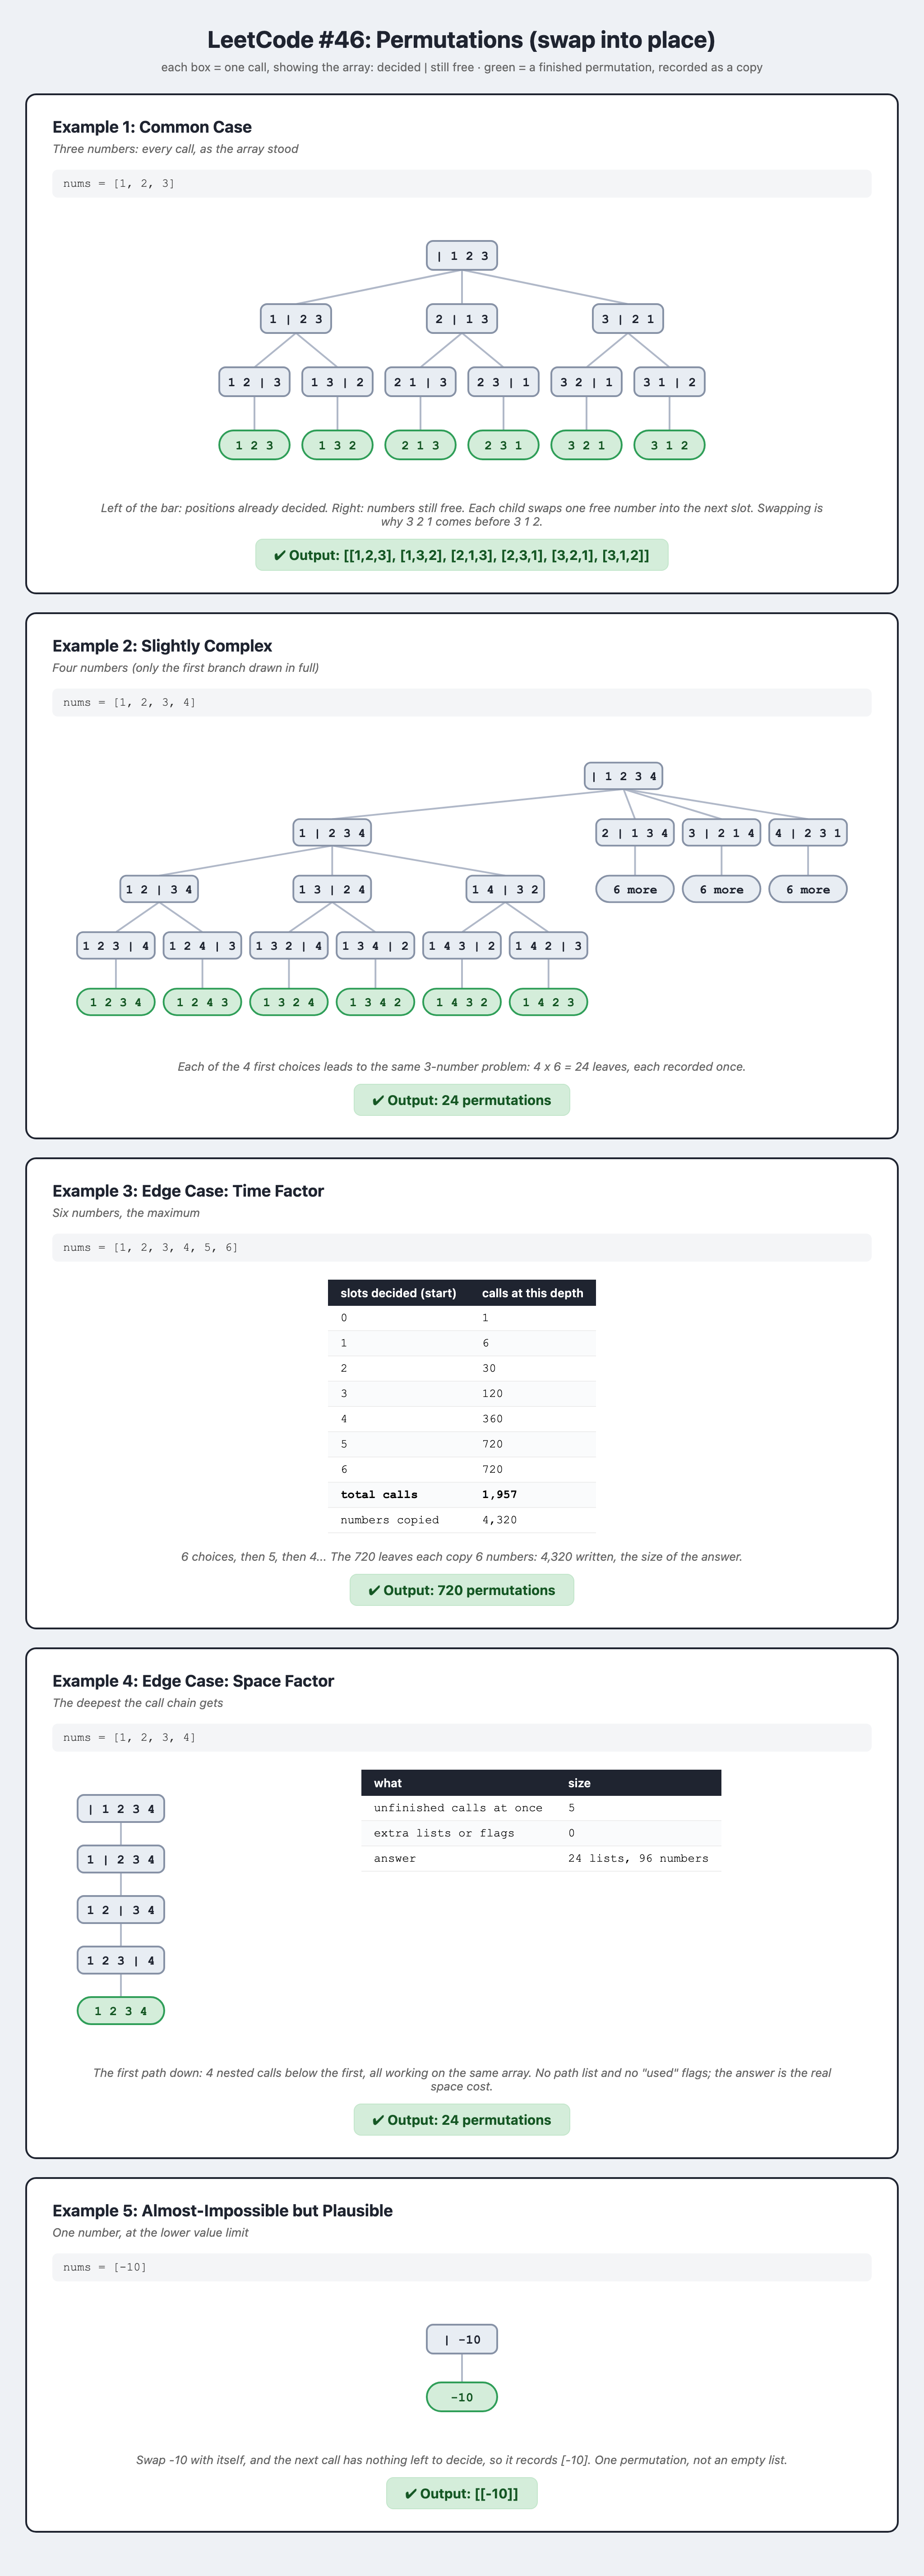

## Watch It Run

*Watch the swap back after the [2, ...] branch: the array returns to [1, 2, 3] so the next choice starts from the original order. Without that undo, some orderings repeat and others never appear.*

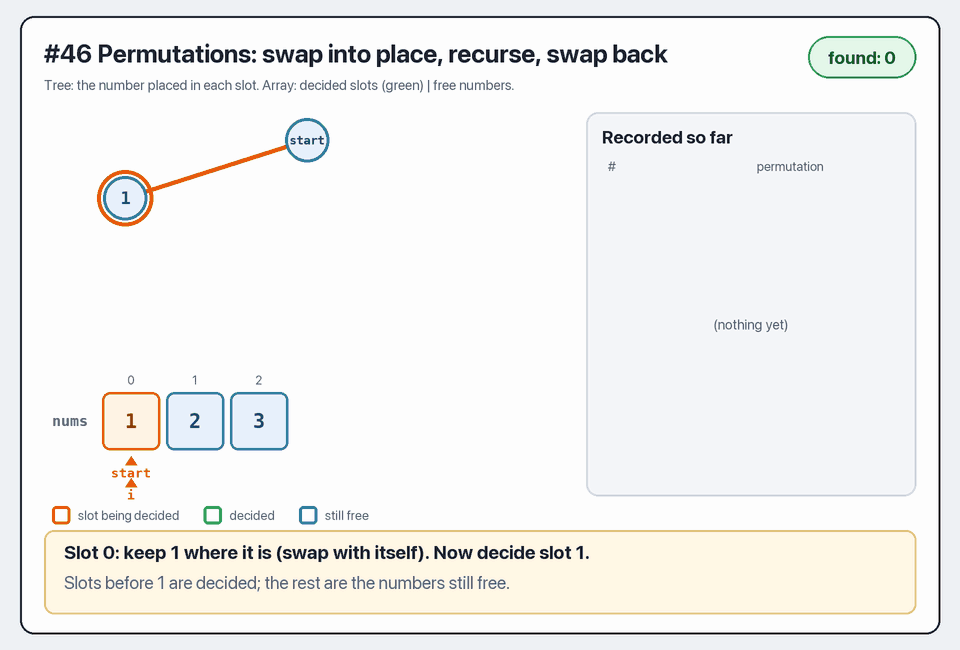

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0046.html)**